# 木をたどる：走査・高さ・ヒープ

第5回で擬似コードとして書いたものを，そのまま Python にして動かす。
確かめたいのは次の 4 つである。

1. 走査は「次を取り出す入れ物」を変えるだけで順序が変わる
2. 木の **高さ** が性能を決める。$\log_2 n$ か $n$ か
3. ヒープは参照を持たずに **配列** に載る
4. 同じ部分問題をくり返すと，再帰は破滅的に遅くなる

上のセルから順に実行していけばよい。
数値は計算機によって変わるので，自分の環境で出た値を見てほしい。

## 準備

図に日本語を出すための設定である。中身は読み飛ばしてよい。

In [1]:
# 図の準備。手元でも Colab でも動くようにしてある
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager


def japanese_font():
    """日本語が出るフォント名を返す。無ければ入れる（Colab 用）。"""
    for name in ("IPAexGothic", "Noto Sans CJK JP", "IPAPGothic",
                 "Hiragino Sans", "Yu Gothic", "Meiryo"):
        if any(f.name == name for f in font_manager.fontManager.ttflist):
            return name
    import glob
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-ipaexfont-gothic",
                   shell=True, check=False)
    for path in glob.glob("/usr/share/fonts/**/ipaexg.ttf", recursive=True):
        font_manager.fontManager.addfont(path)
    return "IPAexGothic"


matplotlib.rcParams.update({
    "font.family": japanese_font(),
    "font.size": 11,
    "figure.figsize": (6.0, 3.6),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    # 日本語フォントには原則マイナス記号がないため ASCII のハイフンを使う
    "axes.unicode_minus": False,
})

## 二分木を作る

節点は値と左右の子をもつ。配布文書の `Node` と同じものである。

ここでは $(2 + 3) \times 4$ の式の木を作る。
葉が数で，内側の節点が演算子である。

In [2]:
class Node:
    """二分木の節点。"""

    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right

    def __repr__(self):
        return f"Node({self.value!r})"


# (2 + 3) * 4 の式の木
expr = Node("*", Node("+", Node("2"), Node("3")), Node("4"))

expr, expr.left, expr.left.left

(Node('*'), Node('+'), Node('2'))

In [3]:
def show(x, indent=0):
    """木を横に倒して表示する。上が右の部分木になる。"""
    if x is None:
        return
    show(x.right, indent + 1)
    print("    " * indent + str(x.value))
    show(x.left, indent + 1)


show(expr)

    4
*
        3
    +
        2


## 3 つの走査

違うのは **自分を処理する位置** だけである。
再帰呼び出しの順序は左・右で変わらない。

In [4]:
def preorder(x, out=None):
    """自分 -> 左 -> 右"""
    if out is None:
        out = []
    if x is None:
        return out
    out.append(x.value)      # ここが先頭
    preorder(x.left, out)
    preorder(x.right, out)
    return out


def inorder(x, out=None):
    """左 -> 自分 -> 右"""
    if out is None:
        out = []
    if x is None:
        return out
    inorder(x.left, out)
    out.append(x.value)      # ここが真ん中
    inorder(x.right, out)
    return out


def postorder(x, out=None):
    """左 -> 右 -> 自分"""
    if out is None:
        out = []
    if x is None:
        return out
    postorder(x.left, out)
    postorder(x.right, out)
    out.append(x.value)      # ここが最後
    return out


for name, f in (("前順", preorder), ("間順", inorder), ("後順", postorder)):
    print(f"{name}: {' '.join(f(expr))}")

前順: * + 2 3 4
間順: 2 + 3 * 4
後順: 2 3 + 4 *


式の木では，3 つの走査がそれぞれ見慣れた記法に対応する。

| 走査 | 出てくる記法 |
|---|---|
| 前順 | `* + 2 3 4` ポーランド記法（前置記法） |
| 間順 | `2 + 3 * 4` ふつうの書き方。ただし括弧が落ちている |
| 後順 | `2 3 + 4 *` 逆ポーランド記法（後置記法） |

間順だけが括弧を失う。`(2 + 3) * 4` と `2 + (3 * 4)` は別の木なのに，
間順で並べるとどちらも `2 + 3 * 4` になってしまうからである。
前順と後順は括弧なしで木を復元できる。

In [5]:
# 2 + (3 * 4) の木。間順は上と同じ並びになる
expr2 = Node("+", Node("2"), Node("*", Node("3"), Node("4")))

print("(2 + 3) * 4 の間順:", " ".join(inorder(expr)))
print("2 + (3 * 4) の間順:", " ".join(inorder(expr2)))
print()
print("(2 + 3) * 4 の後順:", " ".join(postorder(expr)))
print("2 + (3 * 4) の後順:", " ".join(postorder(expr2)))

(2 + 3) * 4 の間順: 2 + 3 * 4
2 + (3 * 4) の間順: 2 + 3 * 4

(2 + 3) * 4 の後順: 2 3 + 4 *
2 + (3 * 4) の後順: 2 3 4 * +


後順は電卓の作り方そのものである。
左から読んで，数ならスタックに積み，演算子なら 2 つ降ろして計算する。

In [6]:
def evaluate(x):
    """式の木を後順にたどって値を求める。"""
    if x.left is None and x.right is None:
        return int(x.value)
    a = evaluate(x.left)       # 左
    b = evaluate(x.right)      # 右
    if x.value == "+":         # 自分
        return a + b
    if x.value == "*":
        return a * b
    raise ValueError(x.value)


print("(2 + 3) * 4 =", evaluate(expr))
print("2 + (3 * 4) =", evaluate(expr2))

(2 + 3) * 4 = 20
2 + (3 * 4) = 14


## 幅優先（レベル順）はキューで書く

深さ優先の 3 つは再帰，すなわち **スタック** で書けた。
入れ物をキューに変えると，浅いところから順に訪れる走査になる。
手続きの形はほとんど変わらない。

In [7]:
from collections import deque


def levelorder(root):
    """根に近いほうから順に訪れる。"""
    out = []
    q = deque([root])
    while q:
        x = q.popleft()        # キューなので先に入れたものから
        if x is None:
            continue
        out.append(x.value)
        q.append(x.left)
        q.append(x.right)
    return out


def preorder_iter(root):
    """前順を、再帰をやめてスタックで書いたもの。"""
    out = []
    s = [root]
    while s:
        x = s.pop()            # スタックなので後に入れたものから
        if x is None:
            continue
        out.append(x.value)
        s.append(x.right)      # 右を先に積む
        s.append(x.left)
    return out


print("レベル順:", " ".join(levelorder(expr)))
print("前順(反復):", " ".join(preorder_iter(expr)))
print("前順(再帰):", " ".join(preorder(expr)))

レベル順: * + 4 2 3
前順(反復): * + 2 3 4
前順(再帰): * + 2 3 4


違いは `pop()` か `popleft()` か，それだけである。
**走査の種類は，次を取り出す入れ物で決まる。**

## 高さが性能を決める

同じ $n$ 個の節点でも，形によって高さはまるで違う。
もっとも平らな形で $\lfloor \log_2 n \rfloor$，最悪の一列で $n - 1$ である。

In [8]:
def height(x):
    """高さ（辺の数）。空の木は -1。"""
    if x is None:
        return -1
    return 1 + max(height(x.left), height(x.right))


def size(x):
    if x is None:
        return 0
    return 1 + size(x.left) + size(x.right)


def balanced(values):
    """整列済みの列から、もっとも平らな二分木を作る。"""
    if not values:
        return None
    mid = len(values) // 2
    return Node(values[mid],
                balanced(values[:mid]),
                balanced(values[mid + 1:]))


def chain(values):
    """右の子だけをつないだ一列の木。線形リストと同じ形。"""
    root = None
    for v in reversed(values):
        root = Node(v, None, root)
    return root


import math

print(f"{'n':>8}{'平らな木':>10}{'一列の木':>10}{'log2 n':>10}")
for n in (7, 31, 100, 500):          # 一列の木は再帰の上限があるのでここまで
    vs = list(range(n))
    print(f"{n:>8}{height(balanced(vs)):>10}{height(chain(vs)):>10}"
          f"{math.floor(math.log2(n)):>10}")

       n      平らな木      一列の木    log2 n
       7         2         6         2
      31         4        30         4
     100         6        99         6
     500         8       499         8


平らな木の高さは $\lfloor \log_2 n \rfloor$ にぴったり一致する。
一列の木は $n - 1$ である。

根から葉まで降りる手続きは，この高さに比例する。
$n = 500$ なら 8 歩と 499 歩の差になる。
**形を保つ工夫が要る**という問題意識が，第7回の平衡木につながる。

### 再帰の深さには限りがある

一列の木に対して再帰で `height` を呼ぶと，呼び出しスタックが高さの分だけ積まれる。
Python の既定ではおよそ 1000 段で打ち止めになる。

In [9]:
import sys

print("再帰の上限:", sys.getrecursionlimit())

deep = chain(list(range(3000)))
try:
    print(height(deep))
except RecursionError as e:
    print("RecursionError:", e)

再帰の上限: 1000
RecursionError: maximum recursion depth exceeded


これは Python の都合であって，アルゴリズムの誤りではない。
ただし **領域計算量 $O(h)$** が現実の制約として現れた例ではある。
走査をスタックで書き直せば（上の `preorder_iter`）この上限には当たらない。

In [10]:
def height_iter(root):
    """再帰を使わずに高さを求める。レベル順に数える。"""
    if root is None:
        return -1
    h = -1
    q = deque([root])
    while q:
        h += 1
        for _ in range(len(q)):    # その段をまとめて取り出す
            x = q.popleft()
            if x.left is not None:
                q.append(x.left)
            if x.right is not None:
                q.append(x.right)
    return h


print("一列の木の高さ:", height_iter(deep))

一列の木の高さ: 2999


## ヒープは配列に載る

完全二分木は，参照を持たずに配列だけで表せる。
Python の `heapq` は，ふつうの `list` をそのまま最小ヒープとして扱う。

添字が 0 から始まるので，節点 $i$ の子は $2i+1$ と $2i+2$，
親は $\lfloor (i-1)/2 \rfloor$ である。
配布文書は 1 始まりで書いてあるので，そこだけ読み替える。

In [11]:
import heapq
import random

a = []
for v in (5, 3, 8, 1, 9, 2, 7):
    heapq.heappush(a, v)

print("配列:", a)
print("最小:", a[0])
print()
print("整列はされていない。親子の上下関係だけが決まっている:")
for i in range(len(a)):
    left, right = 2 * i + 1, 2 * i + 2
    kids = [a[j] for j in (left, right) if j < len(a)]
    print(f"  A[{i}] = {a[i]}  子: {kids}")

配列: [1, 3, 2, 5, 9, 8, 7]
最小: 1

整列はされていない。親子の上下関係だけが決まっている:
  A[0] = 1  子: [3, 2]
  A[1] = 3  子: [5, 9]
  A[2] = 2  子: [8, 7]
  A[3] = 5  子: []
  A[4] = 9  子: []
  A[5] = 8  子: []
  A[6] = 7  子: []


In [12]:
def is_heap(a):
    """すべての親が子以下であることを確かめる。"""
    for i in range(len(a)):
        for j in (2 * i + 1, 2 * i + 2):
            if j < len(a) and a[i] > a[j]:
                return False
    return True


random.seed(0)
b = [random.randrange(1000) for _ in range(50)]
heapq.heapify(b)

print("ヒープ条件を満たすか:", is_heap(b))
print("整列されているか:", b == sorted(b))
print()
print("取り出すと小さい順に出てくる:")
print([heapq.heappop(b) for _ in range(10)])

ヒープ条件を満たすか: True
整列されているか: False

取り出すと小さい順に出てくる:
[41, 75, 97, 101, 103, 142, 143, 150, 223, 256]


整列されていないのにヒープ条件は満たしている，というのが要点である。
全体を並べ替えるより弱い条件で済ませているぶん，作るのも直すのも安い。

### おまけ：上位 $k$ 個だけ要るとき

全部を整列すれば $O(n \\log n)$ かかる。
小さいほうから $k$ 個だけ欲しいなら，ヒープを使うほうが安く済む。
これが第10回の **優先度付きキュー** につながる。

In [13]:
import time

random.seed(2)
data = [random.randrange(10**9) for _ in range(2_000_000)]
k = 10

t0 = time.perf_counter()
by_sort = sorted(data)[:k]
t1 = time.perf_counter()

t2 = time.perf_counter()
by_heap = heapq.nsmallest(k, data)
t3 = time.perf_counter()

print("結果は同じか:", by_sort == by_heap)
print(f"全部を整列してから先頭 k 個: {t1 - t0:.3f} 秒")
print(f"ヒープで k 個だけ取り出す  : {t3 - t2:.3f} 秒")

結果は同じか: True
全部を整列してから先頭 k 個: 0.667 秒
ヒープで k 個だけ取り出す  : 0.023 秒


## 同じ部分問題をくり返すと

再帰は強力だが，書き方を誤ると破滅的に遅くなる。
フィボナッチ数の定義をそのまま写した手続きで，呼び出し回数を数えてみる。

In [14]:
def fib_naive(n, counter):
    counter[0] += 1
    if n <= 1:
        return n
    return fib_naive(n - 1, counter) + fib_naive(n - 2, counter)


def fib_memo(n, memo, counter):
    counter[0] += 1
    if n in memo:
        return memo[n]
    if n <= 1:
        return n
    memo[n] = fib_memo(n - 1, memo, counter) + fib_memo(n - 2, memo, counter)
    return memo[n]


ns = list(range(2, 29))
naive, memo_counts = [], []
for n in ns:
    c = [0]
    fib_naive(n, c)
    naive.append(c[0])
    c = [0]
    fib_memo(n, {}, c)
    memo_counts.append(c[0])

print(f"{'n':>4}{'素朴':>12}{'メモ化':>10}{'比':>10}")
for n, a_, b_ in zip(ns, naive, memo_counts):
    if n % 4 == 0 or n == ns[-1]:
        print(f"{n:>4}{a_:>12,}{b_:>10}{a_ / b_:>10.0f}")

   n          素朴       メモ化         比
   4           9         7         1
   8          67        15         4
  12         465        23        20
  16       3,193        31       103
  20      21,891        39       561
  24     150,049        47      3193
  28   1,028,457        55     18699


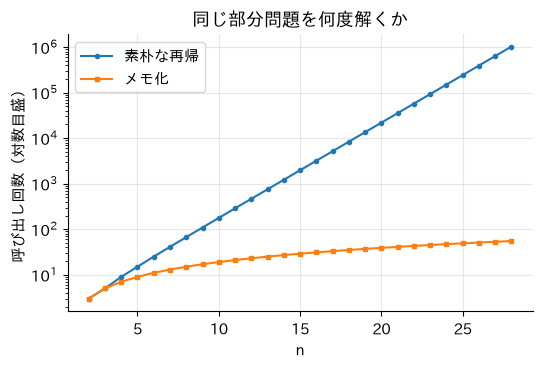

In [15]:
fig, ax = plt.subplots()
ax.semilogy(ns, naive, marker="o", markersize=3, label="素朴な再帰")
ax.semilogy(ns, memo_counts, marker="s", markersize=3, label="メモ化")
ax.set_xlabel("n")
ax.set_ylabel("呼び出し回数（対数目盛）")
ax.set_title("同じ部分問題を何度解くか")
ax.legend()
plt.show()

対数目盛で直線になっているのが素朴な再帰である。
$n$ が 1 増えるごとにおよそ 1.6 倍になる，すなわち **指数時間**である。
メモ化のほうは直線にならない。$O(n)$ だからである。

木の走査が $O(n)$ で済んだのは，各節点を **1 回ずつしか訪れなかった** からであった。
`fib` の呼び出し木には同じ部分問題が何度も現れる。ここが分かれ目である。

## まとめ

- 走査の違いは **自分を処理する位置** だけ。深さ優先か幅優先かは **入れ物** で決まる
- 同じ $n$ でも高さは $\log_2 n$ から $n-1$ まで変わる。**形が性能を決める**
- 再帰の深さは領域計算量 $O(h)$ そのもので，Python では上限として目に見える
- ヒープは整列していないが根が最小。参照なしで配列に載る
- 同じ部分問題をくり返す再帰は指数時間になる。メモ化で $O(n)$ に戻る（第14回）